In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [55]:
def bins_create(x):
    if x <= 50:
        return 'small'
    if x <= 200:
        return 'medium'
    if x <= 1000:
        return 'high'
    else:
        return 'large'

### Linear regression

In [64]:
df_linear = pd.read_csv(r'output\history\boltzmann_mcnn\linear_regression_test_results.csv')
df_linear = df_linear[df_linear['gt'] != 0]
df_linear['mse'] = df_linear['abs_err'] ** 2
df_linear_grouped = df_linear.groupby('dataset').mean()
df_linear_grouped['rmse'] = np.sqrt(df_linear_grouped['mse'])
df_linear_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,203.725559,228.390774,30.559996
ShanghaiTech_part_A,639.722161,964.442586,0.620188
ShanghaiTech_part_B,144.835763,171.438111,2.373411
UCF-QNRF_ECCV18,329.124591,605.142855,5.365108
jhu_crowd_v2.0,329.805667,628.238363,10.377462
ucf-cc-50,1754.963173,2427.932358,0.761531


Text(0, 0.5, 'Predicted')

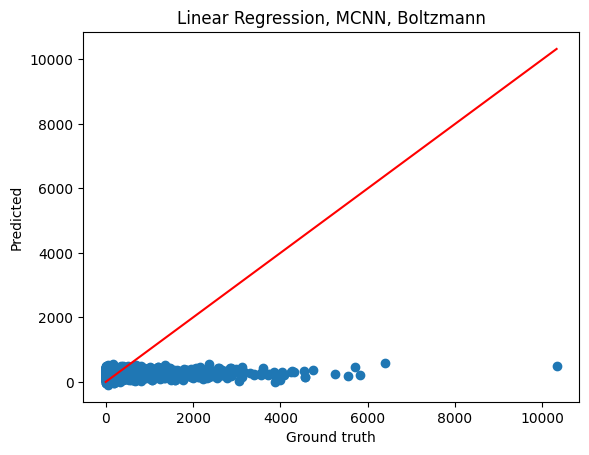

In [57]:
plt.scatter(df_linear['gt'], df_linear['pred'])
plt.plot([0,max(df_linear['gt'])], [0, max(df_linear['gt'])], color='red')
plt.title('Linear Regression, MCNN, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [65]:
df_linear['bins'] = df_linear['gt'].apply(lambda x: bins_create(x))
df_linear.drop(columns='dataset', inplace=True)
df_linear = df_linear.groupby(['bins']).mean()
df_linear['rmse'] = np.sqrt(df_linear['mse'])
df_linear[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,232.870420,309.047205,0.440724
large,1719.185960,2049.699955,0.839231
medium,145.440991,170.335665,1.705486
small,221.968210,240.534910,34.378214


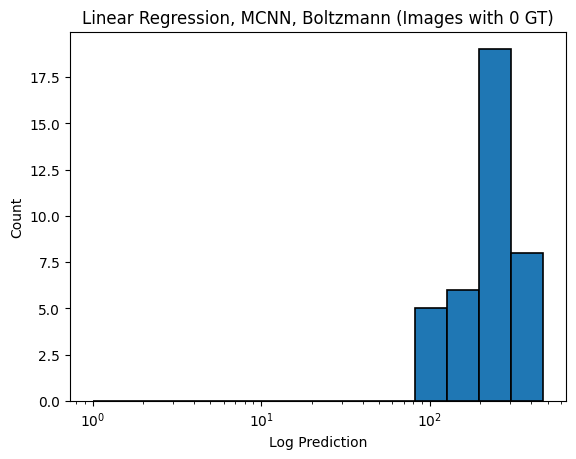

In [59]:
df_linear = pd.read_csv(r'output\history\boltzmann_mcnn\linear_regression_test_results.csv')
df_linear = df_linear[df_linear['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_linear['pred'].max()),
    15
)

plt.hist(
    df_linear['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("Linear Regression, MCNN, Boltzmann (Images with 0 GT)")

plt.show()

### SVM

In [89]:
df_svm = pd.read_csv(r'output\history\boltzmann_mcnn\svm_test_results.csv')
df_svm = df_svm[df_svm['gt'] != 0]
df_svm['mse'] = df_svm['abs_err'] ** 2
df_svm_grouped = df_svm.groupby('dataset').mean()
df_svm_grouped['rmse'] = np.sqrt(df_svm_grouped['mse'])
df_svm_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,58.397851,94.213282,7.905169
ShanghaiTech_part_A,806.068709,1098.956062,0.866018
ShanghaiTech_part_B,82.662988,127.677047,0.574040
UCF-QNRF_ECCV18,290.321293,650.510653,1.396642
jhu_crowd_v2.0,327.989046,685.387422,2.662296
ucf-cc-50,1976.664623,2618.918989,0.935759


Text(0, 0.5, 'Predicted')

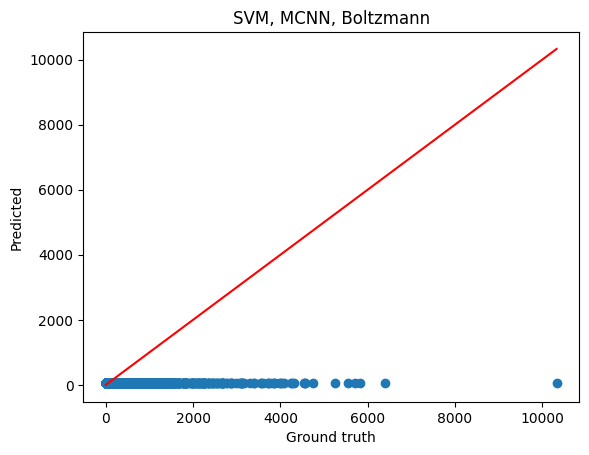

In [74]:
plt.scatter(df_svm['gt'], df_svm['pred'])
plt.plot([0,max(df_svm['gt'])], [0, max(df_svm['gt'])], color='red')
plt.title('SVM, MCNN, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [75]:
df_svm['bins'] = df_svm['gt'].apply(lambda x: bins_create(x))
df_svm.drop(columns='dataset', inplace=True)
df_svm = df_svm.groupby(['bins']).mean()
df_svm['rmse'] = np.sqrt(df_svm['mse'])
df_svm[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,392.899776,448.250994,0.829402
large,1921.372835,2226.436449,0.961159
medium,48.629840,63.477962,0.367332
small,41.275855,43.887385,8.207789


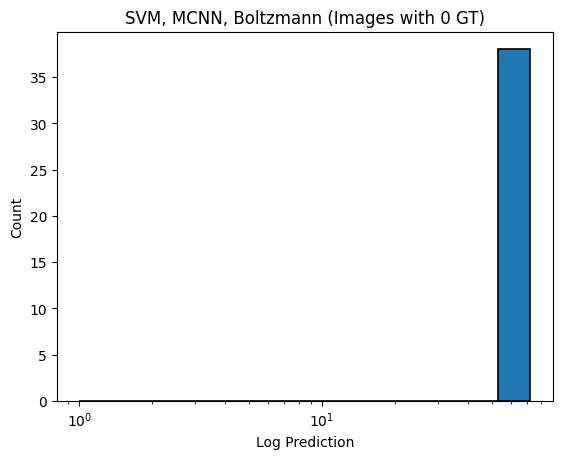

In [76]:
df_svm = pd.read_csv(r'output\history\boltzmann_mcnn\svm_test_results.csv')
df_svm = df_svm[df_svm['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_svm['pred'].max()),
    15
)

plt.hist(
    df_svm['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("SVM, MCNN, Boltzmann (Images with 0 GT)")

plt.show()

### Decision Tree

In [87]:
df_tree = pd.read_csv(r'output\history\boltzmann_mcnn\decision_tree_test_results.csv')
df_tree = df_tree[df_tree['gt'] != 0]
df_tree['mse'] = df_tree['abs_err'] ** 2
df_tree_grouped = df_tree.groupby('dataset').mean()
df_tree_grouped['rmse'] = np.sqrt(df_tree_grouped['mse'])
df_tree_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,363.258965,852.989439,42.632206
ShanghaiTech_part_A,848.473854,1393.634515,1.044027
ShanghaiTech_part_B,319.120255,656.544225,3.954881
UCF-QNRF_ECCV18,529.744381,1230.088734,10.170493
jhu_crowd_v2.0,512.764641,1029.338466,13.252720
ucf-cc-50,1823.430731,2499.247604,0.861121


Text(0, 0.5, 'Predicted')

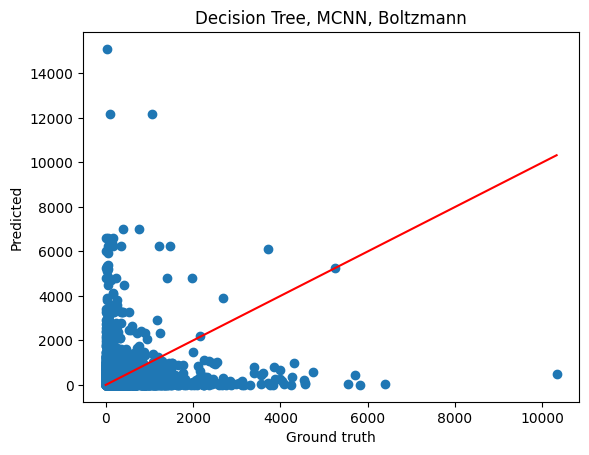

In [78]:
plt.scatter(df_tree['gt'], df_tree['pred'])
plt.plot([0,max(df_tree['gt'])], [0, max(df_tree['gt'])], color='red')
plt.title('Decision Tree, MCNN, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [79]:
df_tree['bins'] = df_tree['gt'].apply(lambda x: bins_create(x))
df_tree.drop(columns='dataset', inplace=True)
df_tree = df_tree.groupby(['bins']).mean()
df_tree['rmse'] = np.sqrt(df_tree['mse'])
df_tree[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,460.859531,737.070216,1.091489
large,1810.262265,2235.553633,0.925879
medium,345.200847,885.917316,3.782728
small,361.925792,971.471459,45.265001


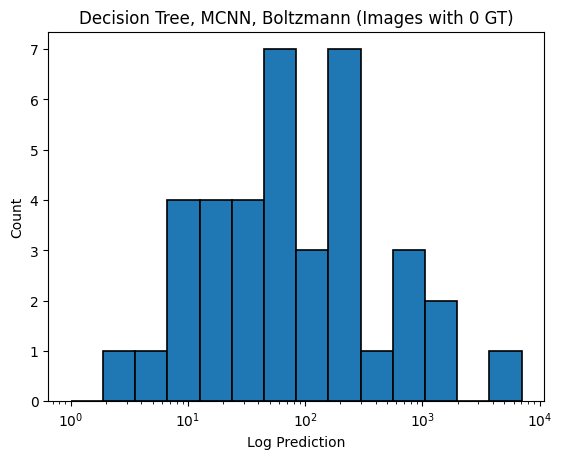

In [80]:
df_tree = pd.read_csv(r'output\history\boltzmann_mcnn\decision_tree_test_results.csv')
df_tree = df_tree[df_tree['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_tree['pred'].max()),
    15
)

plt.hist(
    df_tree['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("Decision Tree, MCNN, Boltzmann (Images with 0 GT)")

plt.show()

### Random forrest

In [81]:
df_rf = pd.read_csv(r'output\history\boltzmann_mcnn\random_forest_test_results.csv')
df_rf = df_rf[df_rf['gt'] != 0]
df_rf['mse'] = df_rf['abs_err'] ** 2
df_rf_grouped = df_rf.groupby('dataset').mean()
df_rf_grouped['rmse'] = np.sqrt(df_rf_grouped['mse'])
df_rf_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,336.216666,365.337528,53.520865
ShanghaiTech_part_A,572.519864,898.901653,0.618270
ShanghaiTech_part_B,272.204333,305.997810,4.267935
UCF-QNRF_ECCV18,401.182430,608.382204,8.940900
jhu_crowd_v2.0,377.413551,619.236596,15.857978
ucf-cc-50,1637.022410,2341.250777,0.697748


Text(0, 0.5, 'Predicted')

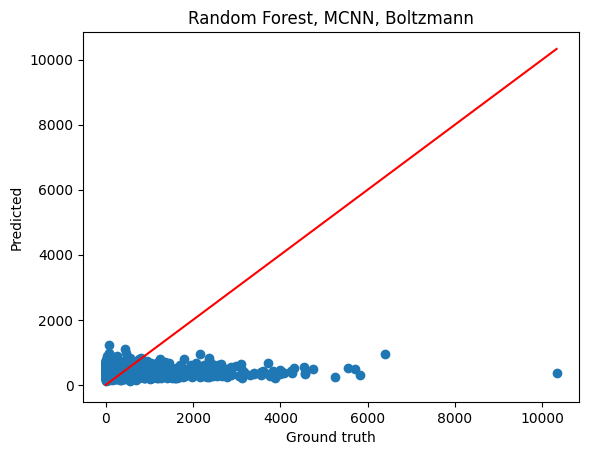

In [82]:
plt.scatter(df_rf['gt'], df_rf['pred'])
plt.plot([0,max(df_rf['gt'])], [0, max(df_rf['gt'])], color='red')
plt.title('Random Forest, MCNN, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [83]:
df_rf['bins'] = df_rf['gt'].apply(lambda x: bins_create(x))
df_rf.drop(columns='dataset', inplace=True)
df_rf = df_rf.groupby(['bins']).mean()
df_rf['rmse'] = np.sqrt(df_rf['mse'])
df_rf[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,197.322613,253.637461,0.447849
large,1584.221890,1939.256408,0.758276
medium,280.002629,307.960043,3.202057
small,361.705923,381.537331,56.188393


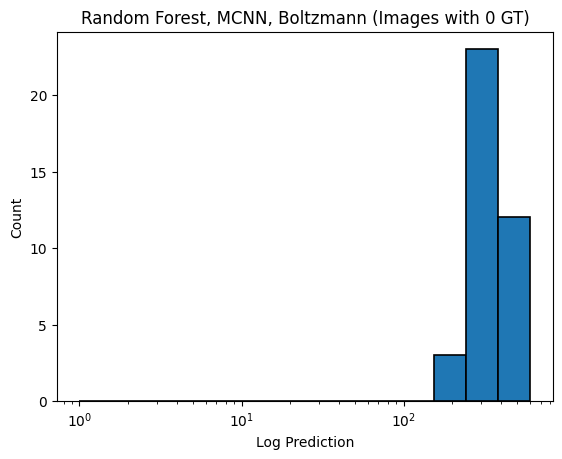

In [84]:
df_rf = pd.read_csv(r'output\history\boltzmann_mcnn\random_forest_test_results.csv')
df_rf = df_rf[df_rf['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_rf['pred'].max()),
    15
)

plt.hist(
    df_rf['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("Random Forest, MCNN, Boltzmann (Images with 0 GT)")

plt.show()